<a href="https://colab.research.google.com/github/Gabrielattie25/busqueda-caminos-metro-Gabriel/blob/main/busqueda_caminos_metro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Estaciones: 62
Conexiones: 62

Ruta de Universidad a Pantitlan
- Universidad
- Copilco
- Miguel Angel de Quevedo
- Viveros
- Coyoacan
- Zapata
- Division del Norte
- Eugenia
- Etiopia
- Centro Medico
- Hospital General
- Ninos Heroes
- Balderas
- Salto del Agua
- Isabel la Catolica
- Pino Suarez
- Merced
- Candelaria
- San Lazaro
- Moctezuma
- Balbuena
- Boulevard Puerto Aereo
- Gomez Farias
- Zaragoza
- Pantitlan
Numero de estaciones: 24
Tiempo aproximado: 48 minutos

Comprobacion con networkx: 48


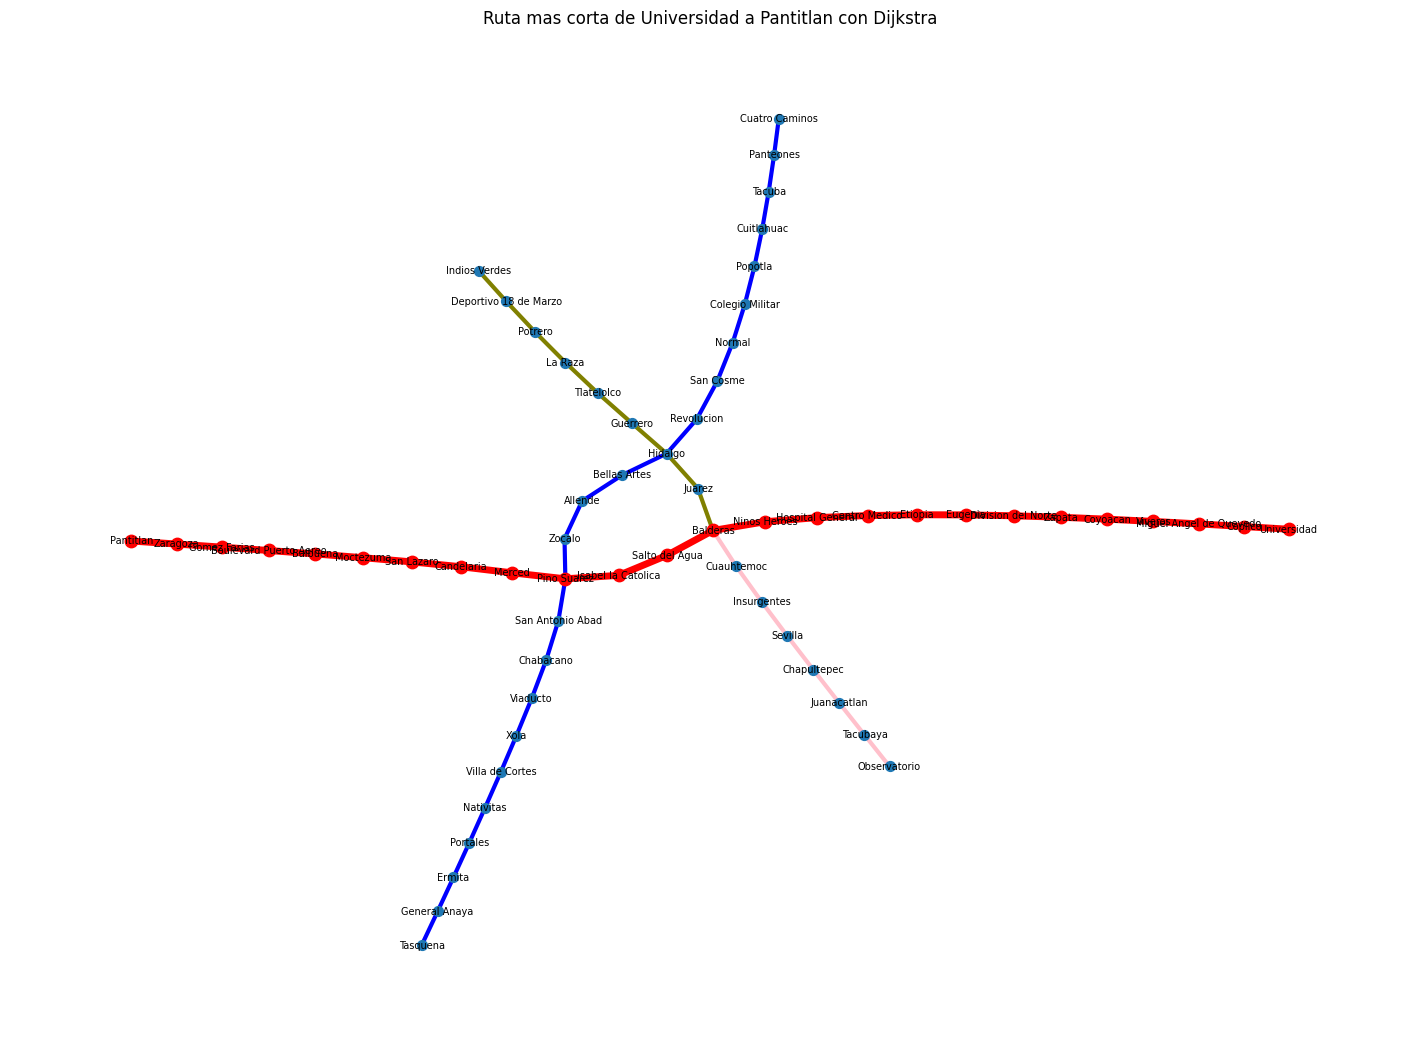

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

linea1 = ["Observatorio", "Tacubaya", "Juanacatlan", "Chapultepec", "Sevilla",
          "Insurgentes", "Cuauhtemoc", "Balderas", "Salto del Agua",
          "Isabel la Catolica", "Pino Suarez", "Merced", "Candelaria",
          "San Lazaro", "Moctezuma", "Balbuena", "Boulevard Puerto Aereo",
          "Gomez Farias", "Zaragoza", "Pantitlan"]

linea2 = ["Cuatro Caminos", "Panteones", "Tacuba", "Cuitlahuac", "Popotla",
          "Colegio Militar", "Normal", "San Cosme", "Revolucion", "Hidalgo",
          "Bellas Artes", "Allende", "Zocalo", "Pino Suarez", "San Antonio Abad",
          "Chabacano", "Viaducto", "Xola", "Villa de Cortes", "Nativitas",
          "Portales", "Ermita", "General Anaya", "Tasquena"]

linea3 = ["Indios Verdes", "Deportivo 18 de Marzo", "Potrero", "La Raza",
          "Tlatelolco", "Guerrero", "Hidalgo", "Juarez", "Balderas",
          "Ninos Heroes", "Hospital General", "Centro Medico", "Etiopia",
          "Eugenia", "Division del Norte", "Zapata", "Coyoacan", "Viveros",
          "Miguel Angel de Quevedo", "Copilco", "Universidad"]

G = nx.Graph()

for linea, color in [(linea1, "pink"), (linea2, "blue"), (linea3, "olive")]:
    for i in range(len(linea) - 1):
        G.add_edge(linea[i], linea[i + 1], color=color, weight=2)

print("Estaciones:", G.number_of_nodes())
print("Conexiones:", G.number_of_edges())


def dijkstra(G, inicio, fin):
    distancia = {}
    anterior = {}
    for estacion in G.nodes:
        distancia[estacion] = 9999
        anterior[estacion] = None
    distancia[inicio] = 0

    pendientes = list(G.nodes)

    while len(pendientes) > 0:
        actual = pendientes[0]
        for estacion in pendientes:
            if distancia[estacion] < distancia[actual]:
                actual = estacion

        pendientes.remove(actual)

        if actual == fin:
            break

        for vecino in G.neighbors(actual):
            nueva = distancia[actual] + G[actual][vecino]["weight"]
            if nueva < distancia[vecino]:
                distancia[vecino] = nueva
                anterior[vecino] = actual

    ruta = []
    estacion = fin
    while estacion is not None:
        ruta.insert(0, estacion)
        estacion = anterior[estacion]

    return ruta, distancia[fin]


inicio = "Universidad"
fin = "Pantitlan"

ruta, tiempo = dijkstra(G, inicio, fin)

print()
print("Ruta de", inicio, "a", fin)
for estacion in ruta:
    print("-", estacion)
print("Numero de estaciones:", len(ruta) - 1)
print("Tiempo aproximado:", tiempo, "minutos")

print()
print("Comprobacion con networkx:", nx.dijkstra_path_length(G, inicio, fin))

colores = [G[u][v]["color"] for u, v in G.edges]
aristas_ruta = []
for i in range(len(ruta) - 1):
    aristas_ruta.append((ruta[i], ruta[i + 1]))

pos = nx.kamada_kawai_layout(G)
plt.figure(figsize=(14, 10))
nx.draw(G, pos, with_labels=True, edge_color=colores, width=3,
        node_size=50, font_size=7)
nx.draw_networkx_nodes(G, pos, nodelist=ruta, node_color="red", node_size=80)
nx.draw_networkx_edges(G, pos, edgelist=aristas_ruta, edge_color="red", width=5)
plt.title("Ruta mas corta de " + inicio + " a " + fin + " con Dijkstra")
plt.savefig("ruta_metro.png")
plt.show()